# 08 — CoAt vs v20b det (subset)

Lit `checkpoints/<run>/history.json` (et `gold_sanity.json` s'il existe).
Même split : **924 train / 653 val**, seed 42.

**Pilote : `RUNS` uniquement.** Commenter une ligne retire un checkpoint.
Pas d'overlays, pas de table `LABELS`. REF = le premier nom qui contient `v20b`.

Référence :
- **v20b_det** : CNN déterministe, terminé. val **0,8364** / gold **0,8842** @ ep10.
- **coat_a_llrd08_det** : parent CoAt (LLRD 0,8). Arrêté ep6 : **0,7913 / 0,7894**.
- **coat_a_llrd07_det** : LLRD 0,7. Terminé, early stop ep11. Best **0,7947 / 0,7916** @ ep7. Pas un gain.
- **coat_b_llrd09_det** : LLRD 0,9. Arrêté ep4 : **0,7507 / 0,7281**. Sous le parent.
- **coat_d_mid14_det** : CAM stage 2 14×14. Terminé, early stop ep11. Best **0,8003 / 0,8111** @ ep7. `mid_proj_l1` ~ 0,002 (branche vivante, faible).
- **coat_c_kd_v20b_det** : KD v20b (ACL, MCL, MM, PF OA, Baker's, Fracture). **En cours**, ep6 **0,8138 / 0,8473**. Devant coat_a à epoch égale.
- **v20h_ssl_ep6 / ep10 / ep15 / ep20** : v20h, encodeur SimCLR à ces epochs, labels Coolin `targets_v3b`. La val AUC n'est pas comparable à v20b_det (soft labels binarisés à 0,5). Lire le **gold**, et la val entre ces runs et **v20b_det_v3b** (même CSV, sans SSL). ep10, ep15 et ep20 apparaissent dès que leur `history.json` existe.
- **v20h_det** : v20h, RadImageNet, labels gpt56sol, seed 42. Témoin sans SSL.
- **v20h_dino_ep11** : même recette que v20h_det, encodeur DINO epoch 11. Comparable en val et en gold à v20h_det (delta > 0,01). La courbe apparaît dès que `history.json` existe.

CoAt n'est un successeur **macro** que s'il bat v20b_det de plus de 0,01
en val **et** gold. Sinon le lire en **spécialiste**. Δ **&lt; 0,01** = bruit.
Gold n=58, jamais pour le checkpoint.

Relancer **load → graphes** pendant coat_c : `history.json` s'écrit chaque epoch.


In [12]:
from __future__ import annotations

import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
CKPT = ROOT / "checkpoints"

# Seul levier du notebook : commenter une ligne pour exclure un run.
# REF = premier nom qui contient "v20b".
RUNS = [
    "subset_v20b_crop130_det_frac025",        # CNN det seed 42 (REF), labels gpt56sol
    "subset_v20h_crop130_det_frac025",         # v20h RadImageNet, gpt56sol, seed 42
    "subset_v20h_crop130_dino_ep11_frac025",   # v20h, encodeur DINO ep11, memes labels
    "subset_v20h_crop130_ssl_ep6_v3b_frac025",  # v20h, encodeur SimCLR ep6, labels Coolin v3b
    "subset_v20h_crop130_ssl_ep10_v3b_frac025", # SimCLR ep10, meme subset
    "subset_v20h_crop130_ssl_ep15_v3b_frac025", # SimCLR ep15, meme subset
    "subset_v20h_crop130_ssl_ep20_v3b_frac025", # SimCLR ep20, meme subset
    "subset_v20b_crop130_det_v3b_frac025",    # meme CSV, sans SSL. Val incomparable a la REF ; gold oui.
    # lr 1e-4 uniforme (mort)
    # "subset_v20b_crop130_frac025",
    # "subset_v20e_crop130_det_frac025",
    # "subset_vit_dinov3_e_crop130_frac025",
    # "subset_vit_k_llrd08_det_frac025",
    # "subset_vit_k_dp01_det_frac025",
    # "subset_vit_k_ls05_det_frac025",
]

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
    "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]
# Fallback si aucun run ne bat la REF de > 0.01 (debut de train).
DEFAULT_SPECIALIST = ["Contusion", "Effusion", "Baker's", "ACL"]
NOISE = 0.01


def run_label(name: str) -> str:
    s = name[7:] if name.startswith("subset_") else name
    return s.replace("_crop130", "").replace("_frac025", "")


print("ROOT", ROOT)
print("RUNS", RUNS)


ROOT c:\Users\sulta\Documents\RSNA-comp
RUNS ['subset_v20b_crop130_det_frac025', 'subset_v20h_crop130_ssl_ep6_v3b_frac025', 'subset_v20h_crop130_ssl_ep10_v3b_frac025', 'subset_v20h_crop130_ssl_ep15_v3b_frac025', 'subset_v20h_crop130_ssl_ep20_v3b_frac025', 'subset_v20b_crop130_det_v3b_frac025']


In [13]:
def load_run(name: str) -> dict | None:
    d = CKPT / name
    hist_p = d / "history.json"
    if not hist_p.exists():
        print(f"  skip {run_label(name)} : pas de history.json")
        return None
    hist = pd.DataFrame(json.loads(hist_p.read_text(encoding="utf-8")))
    if hist.empty:
        print(f"  skip {run_label(name)} : history.json vide")
        return None
    gold = None
    gp = d / "gold_sanity.json"
    if gp.exists():
        gold = json.loads(gp.read_text(encoding="utf-8"))
    uids = []
    up = d / "train_uids.txt"
    if up.exists():
        uids = [ln.strip() for ln in up.read_text(encoding="utf-8").splitlines() if ln.strip()]
    best_idx = hist["val_macro_auc"].idxmax()
    best_row = hist.loc[best_idx]
    gold_best = None
    if "gold_macro_auc" in hist.columns and pd.notna(best_row.get("gold_macro_auc")):
        gold_best = float(best_row["gold_macro_auc"])
    return {
        "name": name,
        "label": run_label(name),
        "dir": d,
        "hist": hist,
        "gold": gold,
        "uids": uids,
        "done": gp.exists(),
        "best_epoch": int(best_row["epoch"]),
        "best_val": float(best_row["val_macro_auc"]),
        "best_gold": gold_best,
        "last_epoch": int(hist["epoch"].max()),
        "n_epochs": int(len(hist)),
    }


def line_kw(r: dict) -> dict:
    return dict(marker="o", label=r["label"])


runs = []
print("runs demandes :", [run_label(n) for n in RUNS])
for name in RUNS:
    rec = load_run(name)
    if rec is None:
        continue
    runs.append(rec)
    gold_txt = f"gold {rec['best_gold']:.3f}" if rec["best_gold"] is not None else "gold n/a"
    etat = "termine" if rec["done"] else f"{rec['n_epochs']} epochs"
    print(
        f"  {rec['label']}: {etat} | best val {rec['best_val']:.4f} "
        f"@ ep {rec['best_epoch']} | {gold_txt} | n_train {len(rec['uids']) or '?'}"
    )

if not runs:
    raise SystemExit("aucun history.json — lance d'abord un train subset")

REF = next((n for n in RUNS if "v20b" in n), runs[0]["name"])
print("REF", run_label(REF))


runs demandes : ['v20b_det', 'v20h_ssl_ep6_v3b', 'v20h_ssl_ep10_v3b', 'v20h_ssl_ep15_v3b', 'v20h_ssl_ep20_v3b', 'v20b_det_v3b']
  v20b_det: termine | best val 0.8364 @ ep 10 | gold 0.884 | n_train 924
  v20h_ssl_ep6_v3b: 4 epochs | best val 0.8808 @ ep 4 | gold 0.825 | n_train 924
  skip v20h_ssl_ep10_v3b : pas de history.json
  v20h_ssl_ep15_v3b: 2 epochs | best val 0.8058 @ ep 2 | gold 0.732 | n_train 924
  skip v20h_ssl_ep20_v3b : pas de history.json
  v20b_det_v3b: termine | best val 0.9433 @ ep 10 | gold 0.905 | n_train 924
REF v20b_det


## Tableau résumé

Meilleure epoch = argmax de la val macro-AUC (comme le `best.pt`).


In [14]:
rows = []
for r in runs:
    last = r["hist"].iloc[-1]
    rows.append({
        "run": r["label"],
        "name": r["name"],
        "etat": "termine" if r["done"] else f"{r['n_epochs']} ep",
        "n_train": len(r["uids"]) or None,
        "best_epoch": r["best_epoch"],
        "best_val_auc": r["best_val"],
        "best_gold_auc": r["best_gold"],
        "last_train_loss": float(last["loss"]),
        "last_val_loss": float(last["val_loss"]) if "val_loss" in last else None,
        "last_val_auc": float(last["val_macro_auc"]),
    })
summary = pd.DataFrame(rows).set_index("run")
display(summary.drop(columns=["name"]).round(4))

ref_row = next((row for _, row in summary.iterrows() if row["name"] == REF), None)
if ref_row is not None and len(summary) > 1:
    print("\ndelta vs", run_label(REF), "(best val AUC)")
    for lab, row in summary.iterrows():
        if row["name"] == REF:
            continue
        d = row["best_val_auc"] - ref_row["best_val_auc"]
        print(f"  {lab}: {d:+.4f}  {'(bruit, <0.01)' if abs(d) < NOISE else ''}")


,etat,n_train,best_epoch,best_val_auc,best_gold_auc,last_train_loss,last_val_loss,last_val_auc
run,,,,,,,,
v20b_det,termine,924,10,0.8364,0.8842,0.3394,0.3846,0.8364
v20h_ssl_ep6_v3b,4 ep,924,4,0.8808,0.8247,0.4292,0.4065,0.8808
v20h_ssl_ep15_v3b,2 ep,924,2,0.8058,0.7317,0.4763,0.4451,0.8058
v20b_det_v3b,termine,924,10,0.9433,0.9055,0.3619,0.3660,0.9433



delta vs v20b_det (best val AUC)
  v20h_ssl_ep6_v3b: +0.0444  
  v20h_ssl_ep15_v3b: -0.0306  
  v20b_det_v3b: +0.1069  


## Courbes (tous les runs superposés)

courbes v20b_det: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
courbes v20h_ssl_ep6_v3b: epochs [1, 2, 3, 4]
courbes v20h_ssl_ep15_v3b: epochs [1, 2]
courbes v20b_det_v3b: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


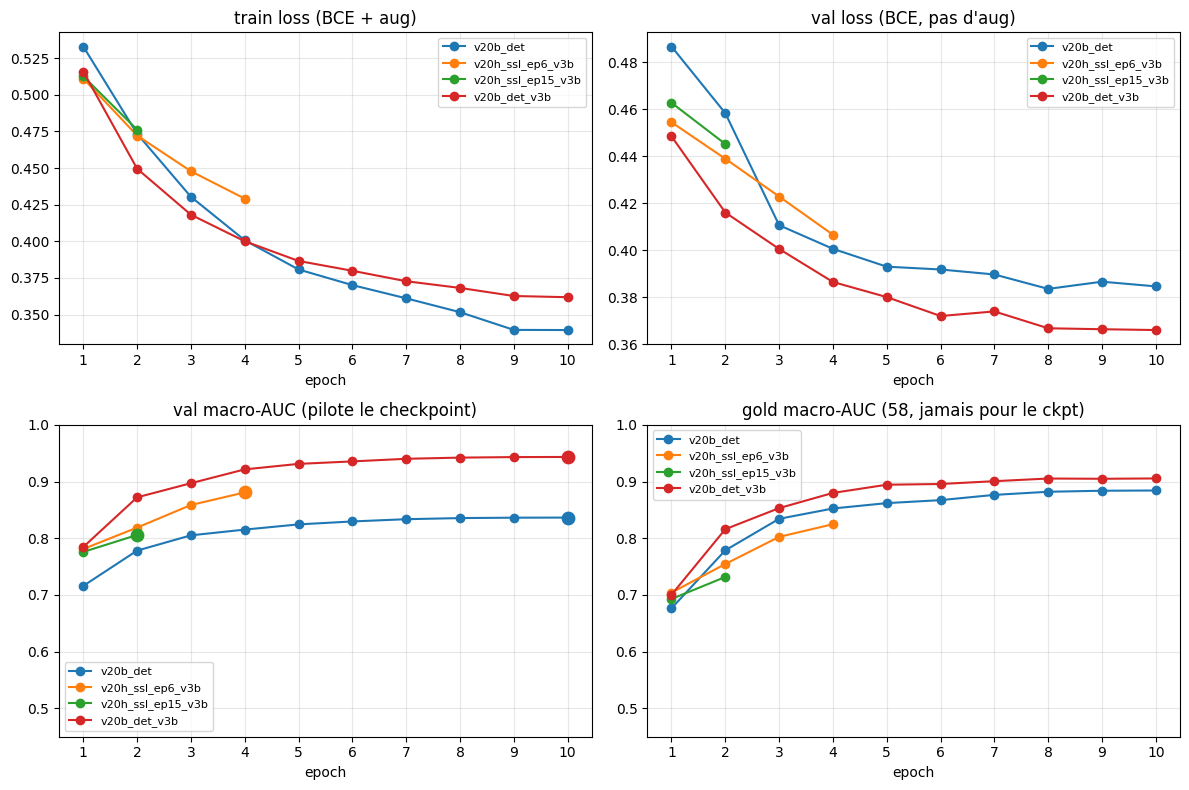

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for r in runs:
    h = r["hist"].sort_values("epoch")
    kw = line_kw(r)
    print(f"courbes {r['label']}: epochs {list(map(int, h.epoch))}")
    axes[0, 0].plot(h.epoch, h.loss, **kw)
    if "val_loss" in h.columns:
        axes[0, 1].plot(h.epoch, h.val_loss, **kw)
    axes[1, 0].plot(h.epoch, h.val_macro_auc, **kw)
    if "gold_macro_auc" in h.columns:
        axes[1, 1].plot(h.epoch, h.gold_macro_auc, **kw)
    axes[1, 0].scatter([r["best_epoch"]], [r["best_val"]], s=80, zorder=5)

emax = max(int(r["hist"]["epoch"].max()) for r in runs)
axes[0, 0].set_title("train loss (BCE + aug)")
axes[0, 1].set_title("val loss (BCE, pas d'aug)")
axes[1, 0].set_title("val macro-AUC (pilote le checkpoint)")
axes[1, 1].set_title("gold macro-AUC (58, jamais pour le ckpt)")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[1, 0].set_ylim(0.45, 1.0)
axes[1, 1].set_ylim(0.45, 1.0)
plt.tight_layout()
plt.show()


## Écart-type des probabilités (val)

Dispersion des scores de validation. Std qui se replie pendant que l'AUC baisse = effondrement (`coat_a_det`, epoch 3). Std qui plonge au dégel puis revient avec l'AUC = choc récupéré (LLRD, epoch 2).

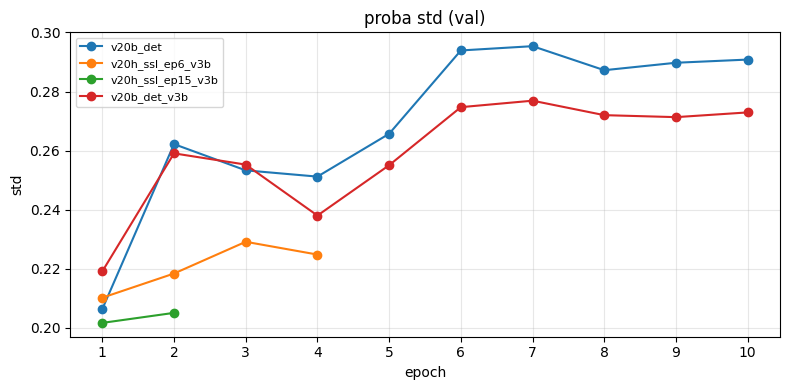

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
emax_std = max(int(r["hist"]["epoch"].max()) for r in runs)
for r in runs:
    h = r["hist"].sort_values("epoch")
    if "proba_std" not in h.columns:
        print(f"  {r['label']}: pas de proba_std")
        continue
    ax.plot(h.epoch, h.proba_std, **line_kw(r))
ax.set_title("proba std (val)")
ax.set_xlabel("epoch")
ax.set_ylabel("std")
ax.set_xticks(range(1, emax_std + 1))
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Suivi à epoch égale vs coat_a (LLRD 0,8)

`LIVES` : coat_c en premier (train en cours), puis les runs terminés.
`PARENT` = coat_a_llrd08. Au-delà de l'ep 6, Δ vs sa dernière epoch (0,7913 / 0,7894).
Pour le KD : séparer cibles distillées / non distillées (les non distillées ne doivent pas baisser).
`mid_proj_l1` (coat_d) : s'il reste ~0, la CAM 14×14 n'est pas utilisée.

Arrêt anticipé coat_c : val ep3 &lt; val ep1 **et** proba std ep3 &lt; 0,12 = signature du lr uniforme.


=== coat_c_kd_v20b_det ===
pas encore de history.json (ecrit en fin d'epoch 1)

=== coat_d_mid14_det ===
pas encore de history.json (ecrit en fin d'epoch 1)

=== coat_a_llrd07_det ===
pas encore de history.json (ecrit en fin d'epoch 1)

=== coat_b_llrd09_det ===
pas encore de history.json (ecrit en fin d'epoch 1)


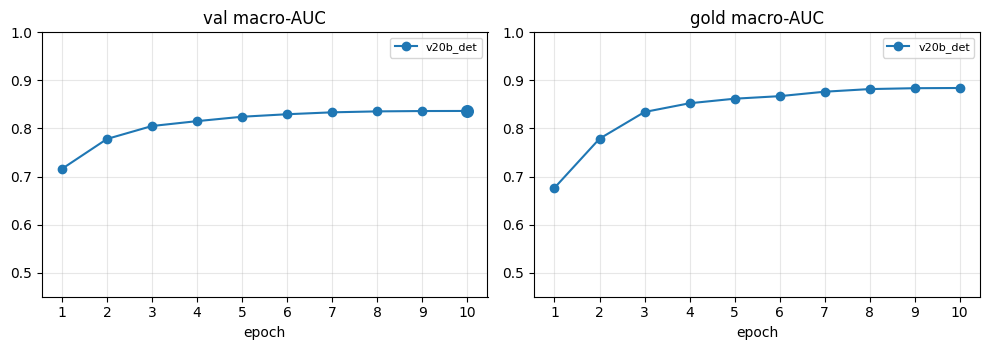

In [17]:
LIVES = [
    "subset_coat_c_kd_v20b_det_frac025",      # en cours
    "subset_coat_d_mid14_det_frac025",
    "subset_coat_a_llrd07_det_frac025",
    "subset_coat_b_llrd09_det_frac025",
]
PARENT = "subset_coat_a_llrd08_det_frac025"
DEAD_STD = 0.12

by_name = {r["name"]: r for r in runs}
METRICS = [("val_macro_auc", "val"), ("gold_macro_auc", "gold"), ("proba_std", "std")]


def per_epoch(name: str) -> pd.DataFrame | None:
    r = by_name.get(name)
    if r is None:
        return None
    return r["hist"].set_index("epoch")


def kd_targets(name: str) -> list[str]:
    p = CKPT / name / "distil.json"
    if not p.exists():
        return []
    return list(json.loads(p.read_text(encoding="utf-8")).get("targets", []))


def track_live(live_name: str) -> None:
    live, parent, ref = per_epoch(live_name), per_epoch(PARENT), per_epoch(REF)
    print(f"\n=== {run_label(live_name)} ===")
    if live is None:
        print("pas encore de history.json (ecrit en fin d'epoch 1)")
        return
    cols = {}
    for name, h in [(live_name, live), (PARENT, parent), (REF, ref)]:
        if h is None:
            continue
        for m, short in METRICS:
            cols[f"{run_label(name)} {short}"] = h[m].reindex(live.index)
    track = pd.DataFrame(cols)
    for name, h in [(PARENT, parent), (REF, ref)]:
        if h is None:
            continue
        for m, short in METRICS[:2]:
            track[f"Δ{short} vs {run_label(name)}"] = live[m] - h[m].reindex(live.index)
    if "distil_loss" in live.columns:
        track["kd loss"] = live["distil_loss"]
    if "mid_proj_l1" in live.columns:
        track["mid_proj_l1"] = live["mid_proj_l1"]
    delta_cols = [c for c in track.columns if c.startswith("Δ")]
    display(
        track.style.format("{:.4f}", na_rep="—")
        .format("{:+.4f}", subset=delta_cols, na_rep="—")
        .background_gradient(cmap="RdYlGn", vmin=-0.05, vmax=0.05, subset=delta_cols)
    )

    last = int(live.index.max())
    print(f"{last} epoch(s) | best val {live.val_macro_auc.max():.4f} "
          f"@ ep {int(live.val_macro_auc.idxmax())}")
    if 3 in live.index and 1 in live.index:
        dead = (live.val_macro_auc[3] < live.val_macro_auc[1]
                and live.proba_std[3] < DEAD_STD)
        print("controle ep3 :", "MORT (signature lr uniforme) -> couper le train"
              if dead else "vivant (pas la signature lr uniforme)")
    else:
        print(f"controle ep3 : en attente (epochs {list(map(int, live.index))})")
    if parent is not None:
        p_ep = last if last in parent.index else int(parent.index.max())
        dv = live.val_macro_auc[last] - parent.val_macro_auc[p_ep]
        dg = live.gold_macro_auc[last] - parent.gold_macro_auc[p_ep]
        note = "" if p_ep == last else f" (parent arrete ep {p_ep})"
        print(f"ep {last} vs {run_label(PARENT)} ep {p_ep}{note} : "
              f"Δval {dv:+.4f} | Δgold {dg:+.4f}")
    if ref is not None and last in ref.index:
        dv = live.val_macro_auc[last] - ref.val_macro_auc[last]
        dg = live.gold_macro_auc[last] - ref.gold_macro_auc[last]
        print(f"ep {last} vs {run_label(REF)} : Δval {dv:+.4f} | Δgold {dg:+.4f}")

    kd = kd_targets(live_name)
    if kd and parent is not None:
        ep = min(last, int(parent.index.max()))
        rows = []
        for t in TARGETS:
            col = f"auc_{t}"
            if col in live.columns and col in parent.columns:
                rows.append({"cible": t, "KD": "oui" if t in kd else "non",
                             "Δ vs parent": live.loc[ep, col] - parent.loc[ep, col]})
        kd_df = pd.DataFrame(rows)
        means = kd_df.groupby("KD")["Δ vs parent"].mean()
        print(f"KD ep {ep} vs {run_label(PARENT)} : Δ moyen cibles distillees "
              f"{means.get('oui', float('nan')):+.4f} | non distillees "
              f"{means.get('non', float('nan')):+.4f}")
        display(
            kd_df.set_index("cible").style.format({"Δ vs parent": "{:+.4f}"})
            .background_gradient(cmap="RdYlGn", vmin=-0.05, vmax=0.05,
                                 subset=["Δ vs parent"])
        )


for name in LIVES:
    track_live(name)

# Courbe live vs parent vs REF (coat_c en tete de LIVES).
focus = [n for n in (LIVES[0], PARENT, REF) if n in by_name]
if focus:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
    emax_f = max(int(by_name[n]["hist"]["epoch"].max()) for n in focus)
    for name in focus:
        h = by_name[name]["hist"].sort_values("epoch")
        kw = line_kw(by_name[name])
        axes[0].plot(h.epoch, h.val_macro_auc, **kw)
        if "gold_macro_auc" in h.columns:
            axes[1].plot(h.epoch, h.gold_macro_auc, **kw)
        axes[0].scatter(
            [by_name[name]["best_epoch"]], [by_name[name]["best_val"]],
            s=70, zorder=5,
        )
    axes[0].set_title("val macro-AUC")
    axes[1].set_title("gold macro-AUC")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.set_xticks(range(1, emax_f + 1))
        ax.set_ylim(0.45, 1.0)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## AUC par cible à la meilleure epoch

Barres = les 12 findings. En **gras** : un run y est **spécialiste** (bat la REF de &gt; 0,01).


specialiste vs v20b_det (Δ > 0.01) : ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,subset_v20b_crop130_det_frac025,subset_v20h_crop130_ssl_ep6_v3b_frac025,subset_v20h_crop130_ssl_ep15_v3b_frac025,subset_v20b_crop130_det_v3b_frac025,d_subset_v20h_crop130_ssl_ep6_v3b_frac025,d_subset_v20h_crop130_ssl_ep15_v3b_frac025,d_subset_v20b_crop130_det_v3b_frac025
ACL,0.793000,0.844000,0.743000,0.900000,0.051000,-0.050000,0.107000
MCL,0.789000,0.774000,0.690000,0.970000,-0.015000,-0.099000,0.181000
Medial Meniscus,0.917000,0.923000,0.810000,0.977000,0.005000,-0.107000,0.059000
Lateral Meniscus,0.807000,0.775000,0.727000,0.886000,-0.032000,-0.080000,0.079000
Medial OA,0.858000,0.940000,0.893000,0.966000,0.082000,0.035000,0.108000
Lateral OA,0.796000,0.906000,0.868000,0.940000,0.110000,0.072000,0.144000
PF OA,0.824000,0.803000,0.764000,0.894000,-0.021000,-0.060000,0.070000
Effusion,0.823000,0.958000,0.952000,0.949000,0.135000,0.129000,0.126000
Synovitis,0.845000,0.919000,0.901000,0.935000,0.074000,0.056000,0.090000
Baker's,0.906000,0.824000,0.746000,0.971000,-0.082000,-0.160000,0.065000


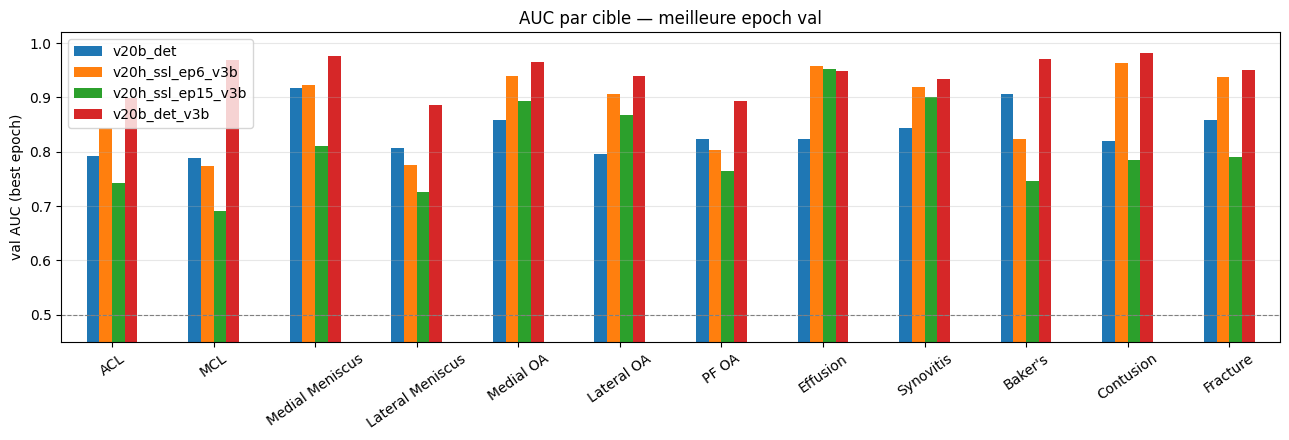

In [18]:
per = {}
for r in runs:
    row = r["hist"].loc[r["hist"]["val_macro_auc"].idxmax()]
    per[r["name"]] = {t: float(row[f"auc_{t}"]) for t in TARGETS if f"auc_{t}" in row.index}
per_df = pd.DataFrame(per).reindex(TARGETS)

vit_names = [r["name"] for r in runs if r["name"] != REF]
FOCUS = list(DEFAULT_SPECIALIST)
if REF in per_df.columns and vit_names:
    FOCUS = []
    for t in TARGETS:
        dmax = float((per_df.loc[t, vit_names] - per_df.loc[t, REF]).max())
        if dmax > NOISE:
            FOCUS.append(t)
    if not FOCUS:
        FOCUS = list(DEFAULT_SPECIALIST)
        print(f"aucun specialiste > 0.01 vs {run_label(REF)} (train trop tot ?) → fallback", FOCUS)
    else:
        print(f"specialiste vs {run_label(REF)} (Δ > 0.01) :", FOCUS)

if REF in per_df.columns:
    for c in [x for x in per_df.columns if x != REF]:
        per_df[f"d_{c}"] = per_df[c] - per_df[REF]

display(per_df.round(3).style.apply(
    lambda s: ["font-weight: bold" if s.name in FOCUS else "" for _ in s],
    axis=1,
))

plot_df = per_df[[r["name"] for r in runs]].rename(
    columns={r["name"]: r["label"] for r in runs}
)
ax = plot_df.plot(kind="bar", figsize=(13, 4.5), rot=35)
ax.set_ylabel("val AUC (best epoch)")
ax.set_ylim(0.45, 1.02)
ax.set_title("AUC par cible — meilleure epoch val")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Delta par cible vs la REF

Positif = le run bat v20b_det. Rouge = spécialiste. Δ &lt; 0,01 = bruit.


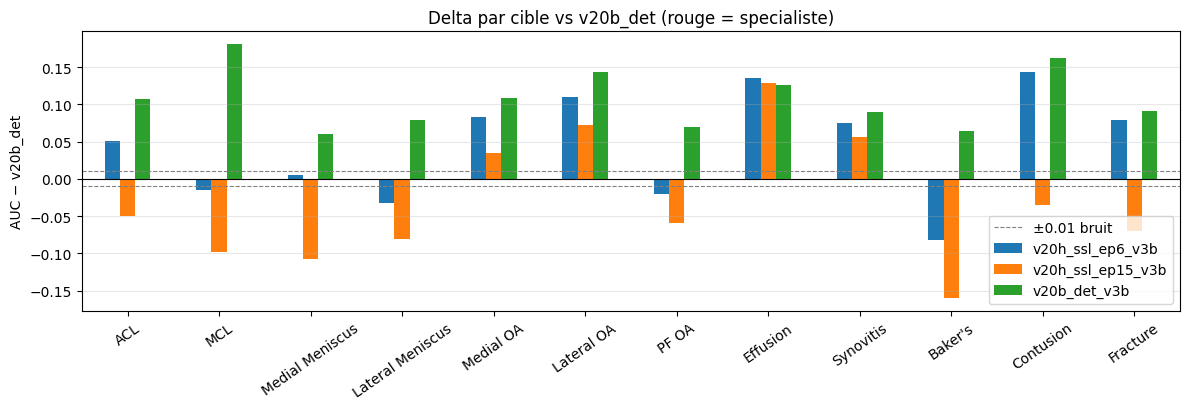

specialiste (val best epoch) :


,subset_v20b_crop130_det_frac025,subset_v20h_crop130_ssl_ep6_v3b_frac025,subset_v20h_crop130_ssl_ep15_v3b_frac025,subset_v20b_crop130_det_v3b_frac025,d_subset_v20h_crop130_ssl_ep6_v3b_frac025,d_subset_v20h_crop130_ssl_ep15_v3b_frac025,d_subset_v20b_crop130_det_v3b_frac025
ACL,0.793,0.844,0.743,0.900,0.051,-0.050,0.107
MCL,0.789,0.774,0.690,0.970,-0.015,-0.099,0.181
Medial Meniscus,0.917,0.923,0.810,0.977,0.005,-0.107,0.059
Lateral Meniscus,0.807,0.775,0.727,0.886,-0.032,-0.080,0.079
Medial OA,0.858,0.940,0.893,0.966,0.082,0.035,0.108
Lateral OA,0.796,0.906,0.868,0.940,0.110,0.072,0.144
PF OA,0.824,0.803,0.764,0.894,-0.021,-0.060,0.070
Effusion,0.823,0.958,0.952,0.949,0.135,0.129,0.126
Synovitis,0.845,0.919,0.901,0.935,0.074,0.056,0.090
Baker's,0.906,0.824,0.746,0.971,-0.082,-0.160,0.065


In [19]:
delta_cols = [c for c in per_df.columns if c.startswith("d_")]
if not delta_cols:
    print(f"pas de delta : il faut REF={run_label(REF)!r} dans RUNS et charge.")
else:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    d = per_df[delta_cols].copy()
    d.columns = [run_label(c[2:]) for c in d.columns]
    colors = ["#c44e52" if t in FOCUS else "#4c72b0" for t in d.index]
    if d.shape[1] == 1:
        ax.bar(range(len(d)), d.iloc[:, 0], color=colors, edgecolor="black", lw=0.3)
        ax.set_xticks(range(len(d)))
        ax.set_xticklabels(d.index, rotation=35, ha="right")
        ax.set_ylabel(f"AUC {d.columns[0]} − {run_label(REF)}")
    else:
        d.plot(kind="bar", ax=ax, rot=35)
        ax.set_ylabel(f"AUC − {run_label(REF)}")
    ax.axhline(0.0, color="black", lw=0.8)
    ax.axhline(NOISE, color="gray", ls="--", lw=0.8, label="±0.01 bruit")
    ax.axhline(-NOISE, color="gray", ls="--", lw=0.8)
    ax.set_title(f"Delta par cible vs {run_label(REF)} (rouge = specialiste)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("specialiste (val best epoch) :")
    display(per_df.loc[FOCUS].round(3))


## Courbes des têtes spécialiste (toutes les epochs)

Là où un run de `RUNS` bat v20b_det. C'est le signal d'ensemble, pas la macro.


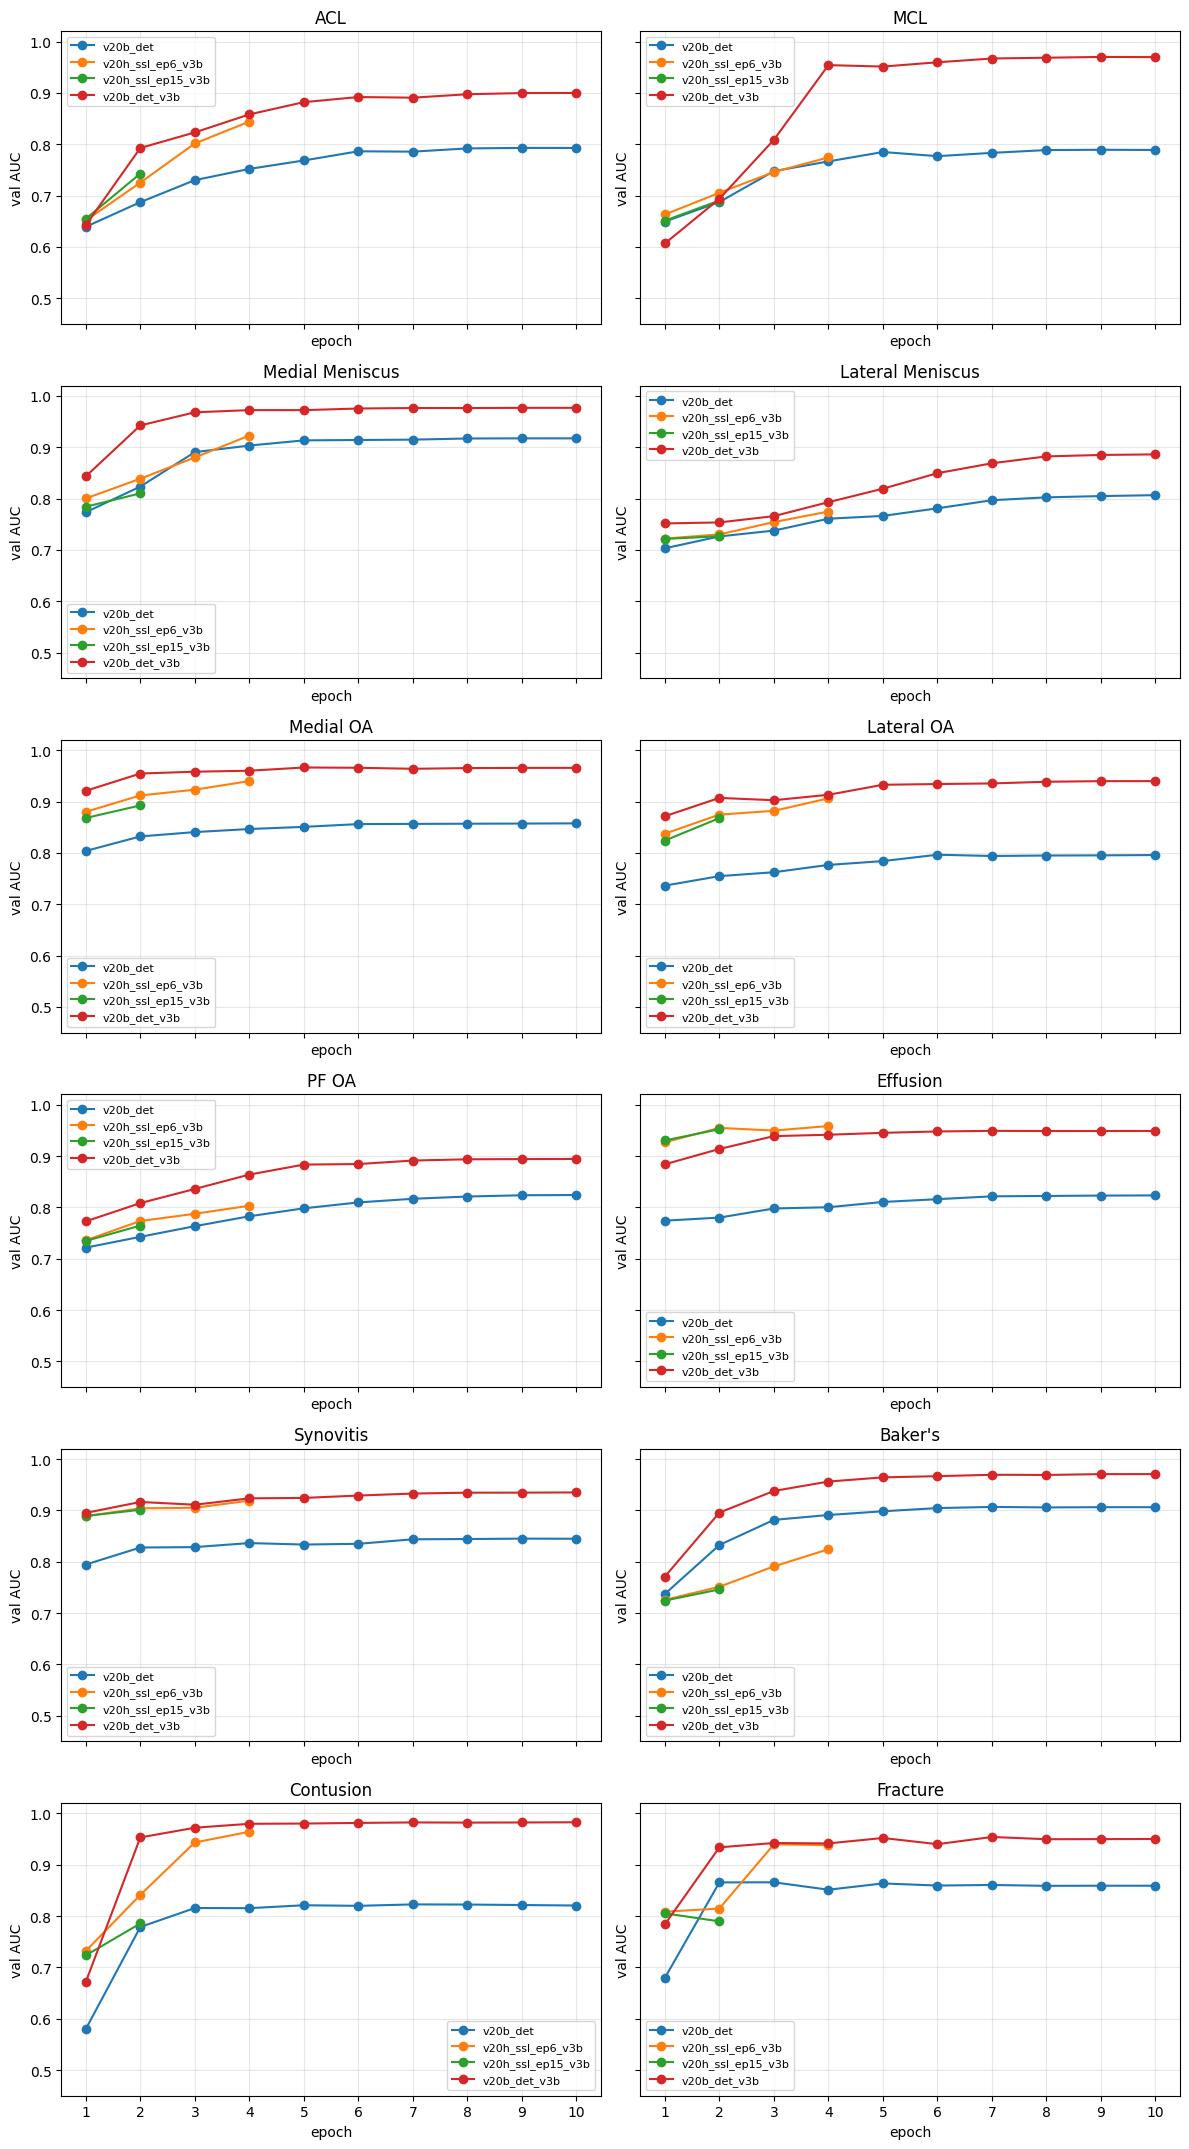

In [20]:
tgts = [t for t in FOCUS if any(f"auc_{t}" in r["hist"].columns for r in runs)]
n = max(len(tgts), 1)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6 * nrows), sharex=True, sharey=True)
if nrows == 1 and ncols == 1:
    axes = [axes]
elif nrows == 1 or ncols == 1:
    axes = list(axes)
else:
    axes = [ax for row in axes for ax in row]
emax = max(int(r["hist"]["epoch"].max()) for r in runs)
for ax, tgt in zip(axes, tgts):
    col = f"auc_{tgt}"
    for r in runs:
        h = r["hist"].sort_values("epoch")
        if col not in h.columns:
            continue
        ax.plot(h.epoch, h[col], **line_kw(r))
    ax.set_title(tgt)
    ax.set_ylim(0.45, 1.02)
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AUC")
for ax in axes[len(tgts):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## Même subset ? (train_uids)

Les YAML subset partagent `train_frac_seed: 42`. L'overlap doit être 100 %.


In [21]:
uid_sets = {r["name"]: set(r["uids"]) for r in runs if r["uids"]}
if len(uid_sets) < 2:
    print("pas assez de train_uids.txt pour comparer")
else:
    names = list(uid_sets)
    ref_n = names[0]
    sref = uid_sets[ref_n]
    ok = True
    print(f"ref UIDs : {run_label(ref_n)} ({len(sref)})")
    for n in names[1:]:
        s = uid_sets[n]
        print(
            f"  {run_label(n)}: {len(s)} | "
            f"inter {len(sref & s)} | seulement ref {len(sref - s)} | "
            f"seulement run {len(s - sref)}"
        )
        if s != sref:
            ok = False
    if ok:
        print("OK : exactement les memes etudes train")
    else:
        print("ATTENTION : subsets differents, la comparaison d'archi n'est plus propre")


ref UIDs : v20b_det (924)
  v20h_ssl_ep6_v3b: 924 | inter 924 | seulement ref 0 | seulement run 0
  v20h_ssl_ep15_v3b: 924 | inter 924 | seulement ref 0 | seulement run 0
  v20b_det_v3b: 924 | inter 924 | seulement ref 0 | seulement run 0
OK : exactement les memes etudes train


## Sanity gold du `best.pt` (si le run est fini)

`gold_sanity.json` n'est écrit qu'à la **fin** du script. Pendant l'entraînement,
utiliser la courbe `gold_macro_auc` ci-dessus.


v20b_det: macro-AUC gold 0.8842  (best epoch 10)
v20h_ssl_ep6_v3b: pas encore de gold_sanity.json
v20h_ssl_ep15_v3b: pas encore de gold_sanity.json
v20b_det_v3b: macro-AUC gold 0.9055  (best epoch 10)


,subset_v20b_crop130_det_frac025,subset_v20b_crop130_det_v3b_frac025,d_subset_v20b_crop130_det_v3b_frac025
ACL,0.915,0.920,0.005
MCL,0.921,0.925,0.005
Medial Meniscus,0.888,0.912,0.024
Lateral Meniscus,0.745,0.766,0.021
Medial OA,0.981,0.992,0.011
Lateral OA,0.857,0.886,0.029
PF OA,0.788,0.816,0.028
Effusion,0.923,0.976,0.053
Synovitis,0.791,0.823,0.032
Baker's,0.967,0.987,0.020


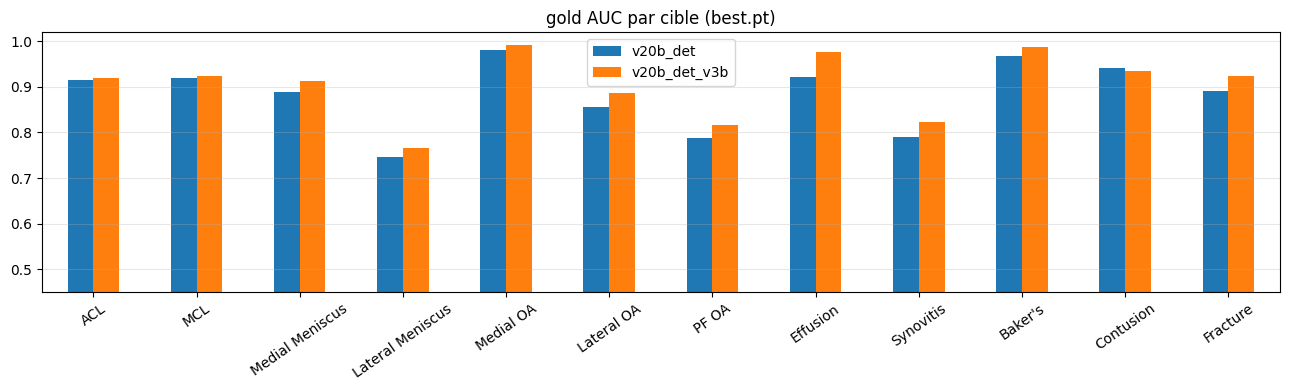

In [22]:
gcols = {}
for r in runs:
    if not r["gold"]:
        print(f"{r['label']}: pas encore de gold_sanity.json")
        continue
    g = r["gold"]
    print(f"{r['label']}: macro-AUC gold {g['macro_auc']:.4f}  (best epoch {g.get('epoch', '?')})")
    gcols[r["name"]] = pd.Series(g["per_target"])
if gcols:
    gdf = pd.DataFrame(gcols).reindex(TARGETS)
    if REF in gdf.columns:
        for c in list(gdf.columns):
            if c != REF:
                gdf[f"d_{c}"] = gdf[c] - gdf[REF]
    display(gdf.round(3))
    plot_g = gdf[[r["name"] for r in runs if r["name"] in gdf.columns]].rename(
        columns={r["name"]: r["label"] for r in runs if r["name"] in gdf.columns}
    )
    plot_g.plot(kind="bar", figsize=(13, 4), rot=35, title="gold AUC par cible (best.pt)")
    plt.ylim(0.45, 1.02)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## Comment lire

1. **Val macro-AUC** : pilote le checkpoint. Δ &lt; 0,01 vs v20b_det → pas de gagnant.
2. **Spécialiste** : têtes en gras / courbes FOCUS, où CoAt &gt; v20b_det + 0,01.
   C'est le critère d'ensemble, pas la macro.
3. **coat_a_det** mort au dégel. **LLRD 0,8** = parent. **0,7 / 0,9** : pas de gain.
   **coat_d** (14×14) : +0,009 val vs parent, sous le seuil 0,01. **coat_c** (KD) :
   en cours, devant coat_a à epoch égale — c'est le run à suivre.
4. **Gold** : n=58, bruité. Ne jamais piloter dessus.

Pour rafraîchir : **re-exécuter à partir de Load**. Pour changer l'analyse : **`RUNS`**.
